# Projet SCI 1402 - Efficacité énergétique des véhicules au Canada

## Notebook 02 - Modélisation et validation approfondie

**Source des données :** Ressources naturelles Canada (RNCan)  
**Période étudiée :** 2015 à 2024  

---

### Objectif du notebook

Ce deuxième notebook poursuit les travaux d'analyse et de modélisation réalisés dans le premier notebook. Il vise à approfondir l'évaluation du modèle prédictif forêt aléatoire retenu pour estimer la consommation combinée de carburant des véhicules, exprimée en litres par 100 kilomètres (L/100 km).

L'objectif principal est d'examiner la précision, la stabilité temporelle et les limites du modèle à partir de données qui n'ont pas été utilisées lors de son entraînement.

### Méthodologie

Le modèle forêt aléatoire est entraîné sur les observations des années 2015 à 2022, puis évalué sur les années 2023 et 2024.

Les analyses portent notamment sur :

  1. **L'analyse des résidus (M020)** : Examen des écarts entre les consommations réelles et prédites, ainsi que des erreurs les plus importantes.

  2. **L'analyse des erreurs par catégorie et niveau de consommation (M021)** : Identification des groupes de véhicules pour lesquels les prédictions sont moins précises.

  3. **La validation chronologique progressive (M022)** : Évaluation du modèle sur plusieurs années successives afin d'examiner sa stabilité temporelle.

  4. **La comparaison des performances annuelles (M023)** : Calcul des indicateurs MAE, RMSE et R² pour les années 2023 et 2024.

  5. **L'analyse de la composition des données (M024)** : Comparaison des caractéristiques des véhicules de 2023 et 2024 afin d'explorer les différences de performance observées.

### Résultats attendus

Ces analyses permettront de mieux comprendre le comportement du modèle, de déterminer dans quelles situations ses prédictions sont les plus fiables et d'examiner les limites de sa généralisation à des années plus récentes.

Les conclusions serviront de fondement aux analyses complémentaires du troisième notebook et à la présentation des résultats du projet.

### Portée et limites

Les observations correspondent aux configurations de véhicules présentes dans les données de RNCan et ne représentent pas les volumes de ventes au Canada.

Les résultats décrivent les performances prédictives du modèle dans le cadre du protocole d'évaluation retenu. Les associations observées ne doivent pas être interprétées comme des relations causales.

### Continuité du projet

Ce deuxième notebook constitue la deuxième partie du développement technique du projet SCI 1402.

Les travaux se poursuivent dans :

  - **Notebook 03 - Analyses complémentaires et finalisation des résultats**  
  Étude approfondie des erreurs, consolidation des performances, production des figures définitives et exportation des résultats.

In [ ]:
# Initialisation du notebook 02
# Projet SCI 1402

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Source officielle de Ressources naturelles Canada
url = (
    "https://open.canada.ca/data/dataset/"
    "98f1a129-f628-4ce4-b24d-6f16bf24dd64/"
    "resource/581ab81d-fe7f-4beb-9f31-e1b8e7552cb6/"
    "download/am2015-2024-cotes-de-consommation-de-carburant.csv"
)

# Création du répertoire pour les données originales
dossier = Path("/content/data/raw")
dossier.mkdir(parents=True, exist_ok=True)

fichier = dossier / "am2015-2024-cotes-de-consommation-de-carburant.csv"

# Téléchargement si le fichier n'existe pas
if not fichier.exists():
    import requests
    reponse = requests.get(url, timeout=60)
    reponse.raise_for_status()
    fichier.write_bytes(reponse.content)

# Lecture du CSV avec l'encodage validé dans le notebook 01
df = pd.read_csv(fichier, encoding="cp1252")

# Copie pour les transformations
df_analyse = df.copy()

# Correction des espaces superflus dans les catégories
df_analyse["Catégorie de véhicule"] = (
    df_analyse["Catégorie de véhicule"].str.strip()
)

print("Dimensions :", df_analyse.shape)
print("Catégories :", df_analyse["Catégorie de véhicule"].nunique())
print("Fichier original conservé :", fichier.exists())


Dimensions : (10060, 15)
Catégories : 16
Fichier original conservé : True


In [ ]:
# Reconstitution du modèle M016
# Séparation chronologique : 2015-2022 / 2023-2024

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

variables_numeriques = [
    "Année modèle",
    "Cylindrée (L)",
    "Cylindres"
]

variables_categorielles = [
    "Catégorie de véhicule",
    "Transmission",
    "Type de carburant"
]

variables = variables_numeriques + variables_categorielles
cible = "Combinée (L/100 km)"

train = df_analyse["Année modèle"] <= 2022
test = df_analyse["Année modèle"] >= 2023

X_train = df_analyse.loc[train, variables]
X_test = df_analyse.loc[test, variables]
y_train = df_analyse.loc[train, cible]
y_test = df_analyse.loc[test, cible]

preparation = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), variables_numeriques),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), variables_categorielles)
])

modele_rf = Pipeline([
    ("preparation", preparation),
    ("modele", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

modele_rf.fit(X_train, y_train)
y_pred_rf = modele_rf.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2 = r2_score(y_test, y_pred_rf)

print("Entraînement :", len(X_train), "observations")
print("Test :", len(X_test), "observations")
print(f"MAE  : {mae:.3f} L/100 km")
print(f"RMSE : {rmse:.3f} L/100 km")
print(f"R²   : {r2:.3f}")


Entraînement : 8352 observations
Test : 1708 observations
MAE  : 0.610 L/100 km
RMSE : 0.910 L/100 km
R²   : 0.897


In [ ]:
# M020-A - Tableau des erreurs de prédiction
# Aucune modification du fichier CSV original

resultats_m020 = df_analyse.loc[test, [
    "Année modèle",
    "Marque",
    "Modèle",
    "Catégorie de véhicule",
    "Cylindrée (L)",
    "Type de carburant",
    "Combinée (L/100 km)"
]].copy()

# Ajout des prédictions du modèle
resultats_m020["Prédiction (L/100 km)"] = y_pred_rf

# Résidu signé : valeur réelle moins valeur prédite
resultats_m020["Résidu"] = (
    resultats_m020["Combinée (L/100 km)"]
    - resultats_m020["Prédiction (L/100 km)"]
)

# Erreur absolue : grandeur de l'écart
resultats_m020["Erreur absolue"] = (
    resultats_m020["Résidu"].abs()
)

print("Nombre de prédictions :", len(resultats_m020))

print("\nRésumé des erreurs :")
print(
    resultats_m020[["Résidu", "Erreur absolue"]]
    .describe()
    .round(3)
)

print("\nLes 10 plus grandes erreurs :")
colonnes = [
    "Année modèle",
    "Marque",
    "Modèle",
    "Combinée (L/100 km)",
    "Prédiction (L/100 km)",
    "Résidu",
    "Erreur absolue"
]

print(
    resultats_m020
    .sort_values("Erreur absolue", ascending=False)
    [colonnes]
    .head(10)
    .round(3)
    .to_string(index=False)
)


Nombre de prédictions : 1708

Résumé des erreurs :
         Résidu  Erreur absolue
count  1708.000        1708.000
mean      0.006           0.610
std       0.910           0.676
min      -4.550           0.001
25%      -0.414           0.150
50%      -0.032           0.386
75%       0.360           0.822
max       5.833           5.833

Les 10 plus grandes erreurs :
 Année modèle        Marque                   Modèle  Combinée (L/100 km)  Prédiction (L/100 km)  Résidu  Erreur absolue
         2024 Mercedes-Benz AMG G 63 4x4 Squared SUV                 21.7                 15.867   5.833           5.833
         2023 Mercedes-Benz AMG G 63 4x4 Squared SUV                 21.7                 15.867   5.833           5.833
         2024          Ford       F-150 Raptor R 4X4                 19.7                 14.144   5.556           5.556
         2023          Ford       F-150 Raptor R 4X4                 19.7                 14.144   5.556           5.556
         2024       Ferra

**M020 - Analyse des erreurs de prédiction**

J'ai comparé les consommations réelles et prédites pour les 1 708 observations de 2023 et 2024. Le résidu moyen est de 0,006 L/100 km, ce qui indique une faible différence moyenne entre les prédictions et les valeurs réelles. L'erreur absolue médiane est de 0,386 L/100 km, mais certaines erreurs dépassent 5 L/100 km. Les plus grandes erreurs concernent notamment des versions particulières de véhicules sportifs et de haute performance. Une analyse des graphiques permettra de vérifier si ces erreurs suivent une tendance.

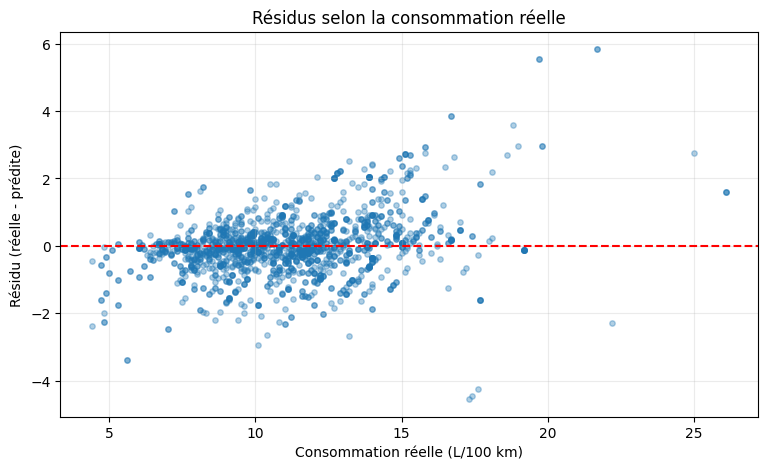

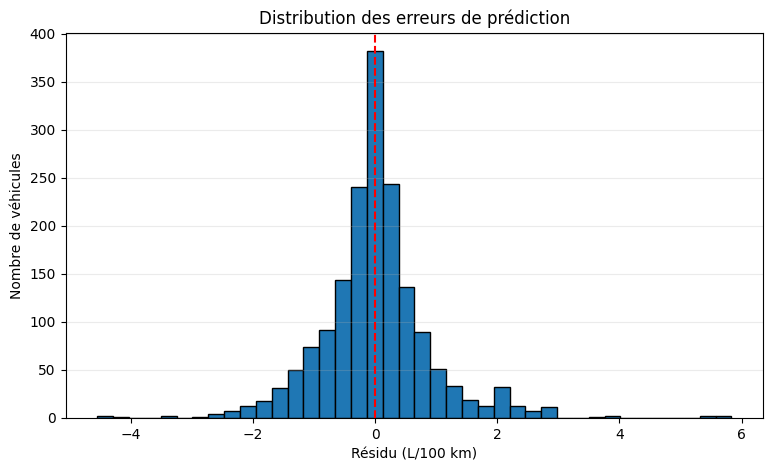

In [ ]:
# M020-B - Visualisation des erreurs de prédiction

import matplotlib.pyplot as plt

reel = resultats_m020["Combinée (L/100 km)"]
residu = resultats_m020["Résidu"]

# Graphique 1 : résidus selon la consommation réelle
plt.figure(figsize=(9, 5))
plt.scatter(reel, residu, alpha=0.35, s=15)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Consommation réelle (L/100 km)")
plt.ylabel("Résidu (réelle - prédite)")
plt.title("Résidus selon la consommation réelle")
plt.grid(alpha=0.25)
plt.show()

# Graphique 2 : distribution des résidus
plt.figure(figsize=(9, 5))
plt.hist(residu, bins=40, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Résidu (L/100 km)")
plt.ylabel("Nombre de véhicules")
plt.title("Distribution des erreurs de prédiction")
plt.grid(axis="y", alpha=0.25)
plt.show()


**M020 - Interprétation des erreurs de prédiction**

L'analyse des résidus montre que le modèle forêt aléatoire produit généralement des prédictions assez proches des consommations réelles. La majorité des erreurs sont concentrées autour de zéro et le résidu moyen est de seulement 0,006 L/100 km.

Cependant, le graphique des résidus montre que les erreurs semblent devenir plus importantes lorsque la consommation des véhicules augmente. Les plus grandes erreurs concernent notamment certaines versions de véhicules sportifs ou de haute performance.

La distribution des résidus est concentrée autour de zéro, mais présente quelques valeurs extrêmes, autant positives que négatives.

Ces résultats montrent que les bonnes performances globales du modèle ne garantissent pas une précision uniforme pour tous les véhicules. Je vais donc poursuivre l'analyse en comparant les erreurs selon les catégories de véhicules.

---

**M021 - Analyse des erreurs par catégorie de véhicule**

Cette étape vise à comparer les performances du modèle selon les différentes catégories de véhicules. Je vais calculer l'erreur absolue moyenne et le résidu moyen pour chaque catégorie, en tenant compte du nombre d'observations.

Erreurs par catégorie de véhicule :
                                       Nombre    MAE  Biais_moyen  Erreur_max
Catégorie de véhicule                                                        
Deux places                               112  1.127        0.204       4.550
Camionnette : petite                       36  0.846        0.277       2.592
Camionnette : ordinaire                   180  0.783       -0.042       5.556
Véhicule utilitaire sport : ordinaire     288  0.701       -0.101       5.833
Sous-compacte                             138  0.631        0.016       2.381
Véhicule utilitaire sport : petit         386  0.559        0.016       3.395
Compacte                                  117  0.526       -0.009       2.505
Familiale : petite                         25  0.483       -0.178       1.958
Intermédiaire                             198  0.411       -0.030       3.593
Grande berline                             96  0.393        0.058       1.880
Familiale : intermédiaire   

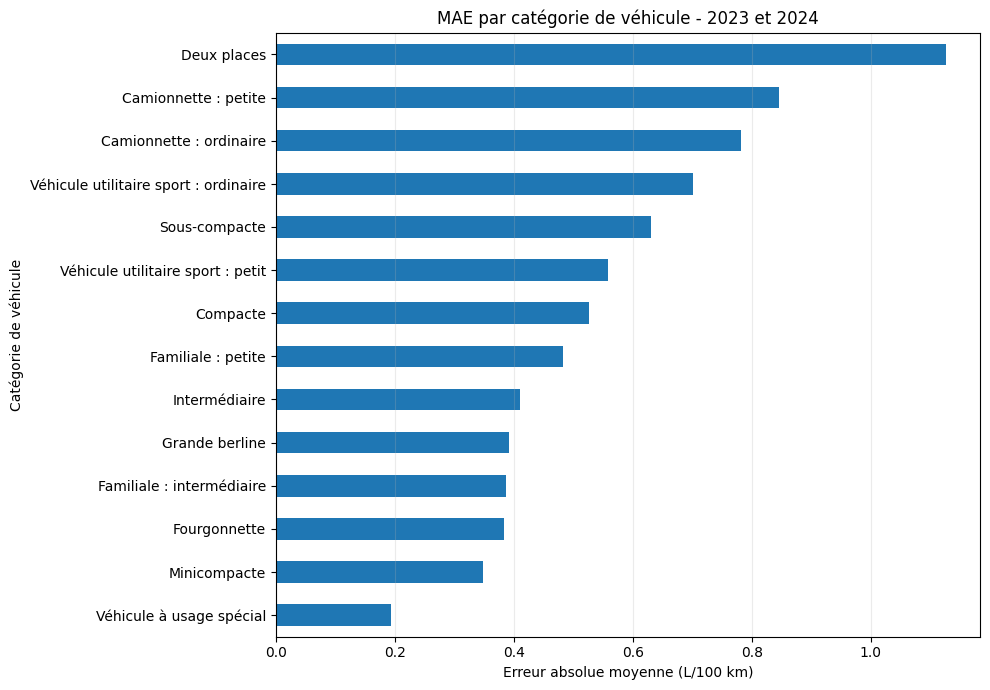

In [ ]:
# M021 - Erreurs par catégorie de véhicule

erreurs_categories = (
    resultats_m020
    .groupby("Catégorie de véhicule")
    .agg(
        Nombre=("Erreur absolue", "size"),
        MAE=("Erreur absolue", "mean"),
        Biais_moyen=("Résidu", "mean"),
        Erreur_max=("Erreur absolue", "max")
    )
    .sort_values("MAE", ascending=False)
)

print("Erreurs par catégorie de véhicule :")
print(erreurs_categories.round(3).to_string())

# Graphique des erreurs absolues moyennes
plt.figure(figsize=(10, 7))

erreurs_categories["MAE"].sort_values().plot(
    kind="barh"
)

plt.xlabel("Erreur absolue moyenne (L/100 km)")
plt.ylabel("Catégorie de véhicule")
plt.title("MAE par catégorie de véhicule - 2023 et 2024")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


**M021 - Interprétation des erreurs par catégorie**

J'ai comparé les erreurs de prédiction du modèle forêt aléatoire selon les catégories de véhicules pour les années 2023 et 2024.

Les résultats montrent que les véhicules deux places présentent l'erreur absolue moyenne la plus élevée, soit 1,127 L/100 km pour 112 observations. Les camionnettes, particulièrement les petites camionnettes, affichent également des erreurs supérieures à la moyenne globale de 0,610 L/100 km.

À l'inverse, plusieurs catégories de voitures présentent des erreurs plus faibles, notamment les minicompactes, les grandes berlines et les voitures intermédiaires.

Les biais moyens sont généralement assez faibles, même lorsque les erreurs absolues sont plus importantes. Le modèle ne semble donc pas systématiquement surestimer ou sous-estimer la consommation de toutes les catégories.

Il faut toutefois interpréter avec prudence les résultats des catégories qui comptent peu d'observations. Cette analyse confirme que la performance globale du modèle ne reflète pas nécessairement sa précision pour chaque type de véhicule.

In [ ]:
# M021-B - Analyse des erreurs selon le niveau de consommation

bornes = [0, 8, 10, 12, 14, 16, float("inf")]

etiquettes = [
    "Moins de 8",
    "8 à moins de 10",
    "10 à moins de 12",
    "12 à moins de 14",
    "14 à moins de 16",
    "16 et plus"
]

resultats_m020["Plage consommation"] = pd.cut(
    resultats_m020["Combinée (L/100 km)"],
    bins=bornes,
    labels=etiquettes,
    right=False
)

erreurs_plages = (
    resultats_m020
    .groupby("Plage consommation", observed=True)
    .agg(
        Nombre=("Erreur absolue", "size"),
        MAE=("Erreur absolue", "mean"),
        Biais_moyen=("Résidu", "mean")
    )
)

print(erreurs_plages.round(3).to_string())


                    Nombre    MAE  Biais_moyen
Plage consommation                            
Moins de 8             210  0.471       -0.332
8 à moins de 10        418  0.474       -0.170
10 à moins de 12       458  0.492       -0.097
12 à moins de 14       353  0.685        0.073
14 à moins de 16       196  0.892        0.610
16 et plus              73  1.399        0.674


**M021 - Conclusion de l'analyse des erreurs**

J'ai poursuivi l'analyse des erreurs en regroupant les véhicules selon leur consommation réelle. Les résultats montrent que la précision du modèle diminue lorsque la consommation augmente.

Pour les véhicules consommant moins de 12 L/100 km, l'erreur absolue moyenne se situe entre 0,471 et 0,492 L/100 km. Elle augmente ensuite progressivement pour atteindre 1,399 L/100 km chez les véhicules consommant 16 L/100 km ou plus.

J'ai également observé une différence dans la direction des erreurs. Le modèle tend à surestimer légèrement la consommation des véhicules les plus économiques et à sous-estimer celle des véhicules les plus énergivores.

Ces observations complètent l'analyse par catégorie de véhicule. Elles suggèrent que le niveau de consommation est associé à la précision des prédictions. Toutefois, elles ne permettent pas de déterminer si cette tendance provient directement du modèle ou des caractéristiques des données.

Cette analyse m'a permis de mieux comprendre les limites des résultats globaux obtenus précédemment.

---

**M022 - Validation chronologique complémentaire**

Dans cette étape, je vais vérifier la stabilité des performances du modèle forêt aléatoire sur plusieurs années.

Pour chaque validation, le modèle sera entraîné avec les années précédentes et évalué sur l'année suivante. Je conserverai les mêmes variables explicatives et les mêmes paramètres afin de comparer les résultats.

Cette méthode permettra de vérifier si les performances observées sur les années 2023 et 2024 sont représentatives des résultats obtenus sur d'autres périodes.

In [ ]:
# M022 - Validation chronologique complémentaire
# Modèle identique à M016, sans modification du CSV

from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

periodes = [
    (2019, 2020),
    (2020, 2021),
    (2021, 2022)
]

resultats_validation = []

for fin_entrainement, annee_validation in periodes:

    # Entraînement : de 2015 jusqu'à l'année indiquée
    masque_train = (
        df_analyse["Année modèle"] <= fin_entrainement
    )

    # Validation : année suivante uniquement
    masque_val = (
        df_analyse["Année modèle"] == annee_validation
    )

    X_train_temp = df_analyse.loc[masque_train, variables]
    y_train_temp = df_analyse.loc[masque_train, cible]

    X_val = df_analyse.loc[masque_val, variables]
    y_val = df_analyse.loc[masque_val, cible]

    # Copie indépendante du modèle de référence
    modele_temp = clone(modele_rf)

    modele_temp.fit(X_train_temp, y_train_temp)
    predictions = modele_temp.predict(X_val)

    resultats_validation.append({
        "Entraînement": f"2015-{fin_entrainement}",
        "Validation": annee_validation,
        "N_train": len(X_train_temp),
        "N_validation": len(X_val),
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_val, predictions)
        ),
        "R2": r2_score(y_val, predictions)
    })

tableau_m022 = pd.DataFrame(resultats_validation)

print("Validation chronologique :")
print(tableau_m022.round(3).to_string(index=False))


Validation chronologique :
Entraînement  Validation  N_train  N_validation   MAE  RMSE    R2
   2015-2019        2020     5431           975 0.552 0.799 0.919
   2015-2020        2021     6406           970 0.585 0.848 0.914
   2015-2021        2022     7376           976 0.543 0.827 0.918


**M022 - Interprétation de la validation chronologique**

J'ai réalisé trois validations chronologiques supplémentaires afin de vérifier si les performances du modèle forêt aléatoire étaient stables d'une année à l'autre.

Pour chaque validation, j'ai entraîné le modèle avec les années précédentes et évalué ses prédictions sur l'année suivante, sans modifier ses paramètres.

Les résultats sont assez semblables pour les années 2020, 2021 et 2022. La MAE varie entre 0,543 et 0,585 L/100 km, tandis que le R² demeure supérieur à 0,91.

Ces résultats sont légèrement meilleurs que ceux obtenus précédemment sur la période 2023–2024, où la MAE était de 0,610 L/100 km et le R² de 0,897.

Cette analyse montre que les performances du modèle sont relativement stables sur les trois années de validation. Elle renforce la confiance dans les résultats, même si elle ne garantit pas que le modèle conservera la même précision sur de futurs véhicules.

In [ ]:
# M023 - Performance du modèle par année de test
# Modèle de référence entraîné sur 2015-2022

resultats_par_annee = []

for annee, groupe in resultats_m020.groupby("Année modèle"):

    reel = groupe["Combinée (L/100 km)"]
    prediction = groupe["Prédiction (L/100 km)"]

    resultats_par_annee.append({
        "Année": annee,
        "Nombre": len(groupe),
        "MAE": mean_absolute_error(reel, prediction),
        "RMSE": np.sqrt(
            mean_squared_error(reel, prediction)
        ),
        "R2": r2_score(reel, prediction),
        "Biais moyen": groupe["Résidu"].mean()
    })

tableau_m023 = pd.DataFrame(resultats_par_annee)

print("Performances par année :")
print(tableau_m023.round(3).to_string(index=False))


Performances par année :
 Année  Nombre   MAE  RMSE    R2  Biais moyen
  2023     919 0.553 0.834 0.914        0.008
  2024     789 0.676 0.991 0.877        0.002


**M023 - Comparaison des performances entre 2023 et 2024**

J'ai comparé les performances du modèle forêt aléatoire séparément pour les années 2023 et 2024. Le modèle utilisé est le même pour les deux années et a été entraîné sur les données de 2015 à 2022.

Les résultats montrent une diminution de la précision en 2024. La MAE passe de 0,553 à 0,676 L/100 km, soit une augmentation d'environ 22 %. La RMSE augmente également, tandis que le R² diminue de 0,914 à 0,877.

Malgré cette différence, les biais moyens restent très proches de zéro pour les deux années. Les erreurs positives et négatives continuent donc de se compenser.

Ces résultats montrent que les performances du modèle peuvent varier selon l'année évaluée. Je ne peux toutefois pas déterminer, à ce stade, si cette différence provient de changements dans les caractéristiques des véhicules ou d'autres facteurs.

---

**M024 - Comparaison des caractéristiques des véhicules en 2023 et 2024**

L'analyse précédente a montré que le modèle forêt aléatoire commet davantage d'erreurs en 2024 qu'en 2023.

Je vais maintenant comparer les caractéristiques des véhicules de ces deux années afin de vérifier si la composition du jeu de données a changé.

Je vais examiner la consommation moyenne, la cylindrée, le nombre de cylindres, les catégories de véhicules et les types de carburant. Cette analyse permettra de chercher des explications possibles à la différence de précision observée, sans modifier le modèle.

In [ ]:
# M024 - Comparaison des caractéristiques 2023 et 2024
# Analyse descriptive, sans modification des données originales

donnees_m024 = df_analyse[
    df_analyse["Année modèle"].isin([2023, 2024])
].copy()

resume_m024 = (
    donnees_m024
    .groupby("Année modèle")
    .agg(
        Nombre=("Modèle", "size"),
        Consommation_moyenne=("Combinée (L/100 km)", "mean"),
        Consommation_mediane=("Combinée (L/100 km)", "median"),
        Cylindree_moyenne=("Cylindrée (L)", "mean"),
        Cylindres_moyen=("Cylindres", "mean"),
        Consommation_max=("Combinée (L/100 km)", "max")
    )
)

print("Caractéristiques générales :")
print(resume_m024.round(3).to_string())

print("\nÉvolution entre 2023 et 2024 :")

for colonne in [
    "Consommation_moyenne",
    "Cylindree_moyenne",
    "Cylindres_moyen"
]:
    valeur_2023 = resume_m024.loc[2023, colonne]
    valeur_2024 = resume_m024.loc[2024, colonne]

    difference = valeur_2024 - valeur_2023
    variation = difference / valeur_2023 * 100

    print(
        f"{colonne} : "
        f"{difference:+.3f} "
        f"({variation:+.2f} %)"
    )


Caractéristiques générales :
              Nombre  Consommation_moyenne  Consommation_mediane  Cylindree_moyenne  Cylindres_moyen  Consommation_max
Année modèle                                                                                                          
2023             919                11.194                  11.0              3.161            5.661              26.1
2024             789                11.099                  11.0              3.097            5.564              26.1

Évolution entre 2023 et 2024 :
Consommation_moyenne : -0.094 (-0.84 %)
Cylindree_moyenne : -0.063 (-2.01 %)
Cylindres_moyen : -0.096 (-1.70 %)


In [ ]:
# M024-B - Répartition des catégories de véhicules
# Comparaison entre 2023 et 2024

effectifs_categories = pd.crosstab(
    donnees_m024["Catégorie de véhicule"],
    donnees_m024["Année modèle"]
)

# Pourcentage de chaque catégorie dans son année
pourcentages_categories = (
    effectifs_categories
    .div(effectifs_categories.sum(axis=0), axis=1)
    * 100
)

comparaison_categories = pd.DataFrame({
    "N_2023": effectifs_categories[2023],
    "N_2024": effectifs_categories[2024],
    "Pct_2023": pourcentages_categories[2023],
    "Pct_2024": pourcentages_categories[2024]
})

comparaison_categories["Variation_pp"] = (
    comparaison_categories["Pct_2024"]
    - comparaison_categories["Pct_2023"]
)

# Trier selon l'ampleur du changement
comparaison_categories = (
    comparaison_categories
    .reindex(
        comparaison_categories["Variation_pp"]
        .abs()
        .sort_values(ascending=False)
        .index
    )
)

print("Répartition des catégories en 2023 et 2024 :")
print(comparaison_categories.round(2).to_string())


Répartition des catégories en 2023 et 2024 :
                                       N_2023  N_2024  Pct_2023  Pct_2024  Variation_pp
Catégorie de véhicule                                                                  
Véhicule utilitaire sport : petit         199     187     21.65     23.70          2.05
Intermédiaire                             114      84     12.40     10.65         -1.76
Grande berline                             59      37      6.42      4.69         -1.73
Véhicule utilitaire sport : ordinaire     148     140     16.10     17.74          1.64
Minicompacte                               49      49      5.33      6.21          0.88
Camionnette : petite                       17      19      1.85      2.41          0.56
Véhicule à usage spécial                    5       0      0.54      0.00         -0.54
Camionnette : ordinaire                    99      81     10.77     10.27         -0.51
Familiale : intermédiaire                   9       6      0.98      0.76  

**M024 - Comparaison des catégories de véhicules**

J'ai comparé la répartition des catégories de véhicules entre 2023 et 2024 pour vérifier si les changements dans la composition du jeu de données pouvaient contribuer à expliquer la hausse des erreurs de prédiction.

Les différences sont généralement modestes. La proportion des petits VUS augmente de 21,65 % à 23,70 %, tandis que celle des VUS ordinaires passe de 16,10 % à 17,74 %. À l'inverse, les voitures intermédiaires et les grandes berlines sont moins représentées en 2024.

Les véhicules deux places, qui présentaient les erreurs les plus élevées lors de M021, occupent une proportion légèrement plus faible en 2024.

Ces résultats ne permettent donc pas d'expliquer directement la diminution de la précision du modèle. Il serait utile de vérifier si les erreurs ont augmenté à l'intérieur de certaines catégories entre les deux années.

In [ ]:
# M024-C - Comparaison de la MAE par catégorie en 2023 et 2024

mae_categories_annees = (
    resultats_m020
    .groupby(["Catégorie de véhicule", "Année modèle"])
    .agg(
        Nombre=("Erreur absolue", "size"),
        MAE=("Erreur absolue", "mean")
    )
    .reset_index()
)

tableau_mae = mae_categories_annees.pivot(
    index="Catégorie de véhicule",
    columns="Année modèle",
    values=["Nombre", "MAE"]
)

comparaison_mae = pd.DataFrame({
    "N_2023": tableau_mae[("Nombre", 2023)],
    "N_2024": tableau_mae[("Nombre", 2024)],
    "MAE_2023": tableau_mae[("MAE", 2023)],
    "MAE_2024": tableau_mae[("MAE", 2024)]
})

comparaison_mae["Variation_MAE"] = (
    comparaison_mae["MAE_2024"]
    - comparaison_mae["MAE_2023"]
)

comparaison_mae = comparaison_mae.sort_values(
    "Variation_MAE",
    ascending=False
)

print("Comparaison des erreurs par catégorie :")
print(comparaison_mae.round(3).to_string())


Comparaison des erreurs par catégorie :
                                       N_2023  N_2024  MAE_2023  MAE_2024  Variation_MAE
Catégorie de véhicule                                                                   
Camionnette : petite                     17.0    19.0     0.652     1.020          0.368
Familiale : petite                       14.0    11.0     0.327     0.681          0.355
Deux places                              61.0    51.0     0.968     1.318          0.350
Véhicule utilitaire sport : petit       199.0   187.0     0.492     0.630          0.138
Véhicule utilitaire sport : ordinaire   148.0   140.0     0.634     0.771          0.138
Grande berline                           59.0    37.0     0.342     0.474          0.132
Compacte                                 63.0    54.0     0.473     0.587          0.114
Sous-compacte                            75.0    63.0     0.592     0.677          0.084
Minicompacte                             49.0    49.0     0.318     0.

**M024 - Comparaison des erreurs par catégorie et par année**

J'ai comparé les erreurs absolues moyennes de chaque catégorie de véhicules entre 2023 et 2024.

Les résultats montrent une augmentation des erreurs dans 11 des 13 catégories présentes les deux années. Les différences les plus importantes concernent les petites camionnettes, les familiales de petite taille et les véhicules deux places. Il faut cependant être prudent avec les catégories qui comptent peu d'observations.

Les petits VUS et les VUS ordinaires présentent également une augmentation des erreurs, alors qu'ils représentent une part importante des véhicules étudiés.

Ces résultats suggèrent que la diminution de la précision en 2024 ne s'explique pas uniquement par les changements dans la répartition des catégories. Le modèle semble également rencontrer davantage de difficultés à prédire certains véhicules à l'intérieur des mêmes catégories.

In [ ]:
# M024-D - Comparaison des carburants entre 2023 et 2024

# Effectifs par carburant et par année
effectifs_carburants = pd.crosstab(
    resultats_m020["Type de carburant"],
    resultats_m020["Année modèle"]
)

# Pourcentages par année
pourcentages_carburants = (
    effectifs_carburants
    .div(effectifs_carburants.sum(axis=0), axis=1)
    * 100
)

# Erreurs moyennes par carburant et par année
mae_carburants = (
    resultats_m020
    .groupby(["Type de carburant", "Année modèle"])
    ["Erreur absolue"]
    .mean()
    .unstack()
)

comparaison_carburants = pd.DataFrame({
    "N_2023": effectifs_carburants[2023],
    "N_2024": effectifs_carburants[2024],
    "Pct_2023": pourcentages_carburants[2023],
    "Pct_2024": pourcentages_carburants[2024],
    "MAE_2023": mae_carburants[2023],
    "MAE_2024": mae_carburants[2024]
})

comparaison_carburants["Variation_MAE"] = (
    comparaison_carburants["MAE_2024"]
    - comparaison_carburants["MAE_2023"]
)

print("Comparaison par type de carburant :")
print(comparaison_carburants.round(3).to_string())


Comparaison par type de carburant :
                   N_2023  N_2024  Pct_2023  Pct_2024  MAE_2023  MAE_2024  Variation_MAE
Type de carburant                                                                       
D                      20      18     2.176     2.281     0.360     0.564          0.205
E                      16       6     1.741     0.760     0.630     0.614         -0.015
X                     392     338    42.655    42.839     0.495     0.617          0.122
Z                     491     427    53.428    54.119     0.604     0.728          0.124


**M024 - Conclusion de l'analyse comparative 2023–2024**

J'ai comparé les caractéristiques des véhicules de 2023 et de 2024 afin de mieux comprendre pourquoi les erreurs du modèle forêt aléatoire sont plus élevées en 2024.

Les résultats montrent que la consommation moyenne, la cylindrée et le nombre moyen de cylindres diminuent légèrement en 2024. La répartition des catégories de véhicules et des principaux carburants change relativement peu.

Cependant, les erreurs augmentent dans la majorité des catégories. J'observe également une augmentation presque identique de la MAE pour les véhicules utilisant de l'essence ordinaire et de l'essence super, qui représentent la grande majorité des observations.

Ces résultats suggèrent que la baisse de précision en 2024 ne provient pas uniquement d'un changement dans la composition générale du jeu de données. Le modèle semble rencontrer davantage de difficultés à prédire certaines configurations de véhicules en 2024.

Je ne peux toutefois pas déterminer la cause exacte de cette différence avec les analyses réalisées jusqu'ici.